# Build a machine learning model to solve CAPTCHA challenges. 

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# Dataset folder
data_dir = "captcha"

# Get all PNG files
files = [
    f for f in os.listdir(data_dir)
    if f.lower().endswith(".png")
]

print("Number of CAPTCHA images:", len(files))

# Show a few filenames
print("\nSample filenames:")
print(files[:10])

Number of CAPTCHA images: 1040

Sample filenames:
['226md.png', '22d5n.png', '2356g.png', '23mdg.png', '23n88.png', '243mm.png', '244e2.png', '245y5.png', '24f6w.png', '24pew.png']


In [2]:
characters = "0123456789abcdefghijklmnopqrstuvwxyz"

char_to_num = {
    char: i for i, char in enumerate(characters)
}

X = []
y = []

for file in files:

    label = file.replace(".png", "")

    # Make sure label has 5 characters
    if len(label) != 5:
        continue

    image_path = os.path.join(data_dir, file)

    # Open image
    image = Image.open(image_path).convert("RGB")

    # Resize
    image = image.resize((100, 30))

    # Convert to numpy array and normalize
    image = np.array(image) / 255.0

    X.append(image)

    # Convert characters to numbers
    encoded_label = [
        char_to_num[char]
        for char in label.lower()
    ]

    y.append(encoded_label)

X = np.array(X)
y = np.array(y)

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)

Image data shape: (1040, 30, 100, 3)
Label data shape: (1040, 5)


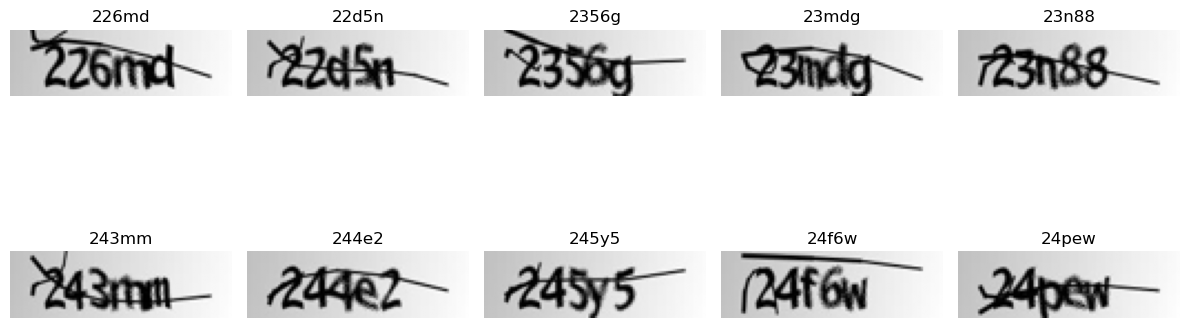

In [3]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X[i])

    # Convert numeric label back to characters
    label = "".join(
        characters[n]
        for n in y[i]
    )

    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 832
Testing images: 208


In [5]:
input_layer = layers.Input(
    shape=(30, 100, 3)
)

# CNN feature extraction
x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu"
)(input_layer)

x = layers.MaxPooling2D(
    (2, 2)
)(x)

x = layers.Conv2D(
    64,
    (3, 3),
    activation="relu"
)(x)

x = layers.MaxPooling2D(
    (2, 2)
)(x)

x = layers.Conv2D(
    128,
    (3, 3),
    activation="relu"
)(x)

x = layers.Flatten()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

# Five character outputs
outputs = []

for i in range(5):

    output = layers.Dense(
        len(characters),
        activation="softmax",
        name=f"char_{i+1}"
    )(x)

    outputs.append(output)

model = models.Model(
    inputs=input_layer,
    outputs=outputs
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 100,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 98,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 49,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 12, 47,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 6, 23, 64) │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 21,     │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 10752)     │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │  1,376,384 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_1 (Dense)      │ (None, 36)        │      4,644 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_2 (Dense)      │ (None, 36)        │      4,644 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_3 (Dense)      │ (None, 36)        │      4,644 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_4 (Dense)      │ (None, 36)        │      4,644 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_5 (Dense)      │ (None, 36)        │      4,644 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,492,852 (5.69 MB)

 Trainable params: 1,492,852 (5.69 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss={
        "char_1": "sparse_categorical_crossentropy",
        "char_2": "sparse_categorical_crossentropy",
        "char_3": "sparse_categorical_crossentropy",
        "char_4": "sparse_categorical_crossentropy",
        "char_5": "sparse_categorical_crossentropy"
    },
    metrics={
        "char_1": "accuracy",
        "char_2": "accuracy",
        "char_3": "accuracy",
        "char_4": "accuracy",
        "char_5": "accuracy"
    }
)

In [7]:
y_train_dict = {
    "char_1": y_train[:, 0],
    "char_2": y_train[:, 1],
    "char_3": y_train[:, 2],
    "char_4": y_train[:, 3],
    "char_5": y_train[:, 4]
}

y_test_dict = {
    "char_1": y_test[:, 0],
    "char_2": y_test[:, 1],
    "char_3": y_test[:, 2],
    "char_4": y_test[:, 3],
    "char_5": y_test[:, 4]
}

In [8]:
history = model.fit(
    X_train,
    y_train_dict,
    validation_split=0.2,
    epochs=20,
    batch_size=32
)

Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - char_1_accuracy: 0.0496 - char_1_loss: 3.4817 - char_2_accuracy: 0.0496 - char_2_loss: 3.4075 - char_3_accuracy: 0.0556 - char_3_loss: 3.4498 - char_4_accuracy: 0.0767 - char_4_loss: 3.4541 - char_5_accuracy: 0.0647 - char_5_loss: 3.4434 - loss: 17.2426 - val_char_1_accuracy: 0.0539 - val_char_1_loss: 3.3022 - val_char_2_accuracy: 0.0539 - val_char_2_loss: 3.2619 - val_char_3_accuracy: 0.0479 - val_char_3_loss: 3.2815 - val_char_4_accuracy: 0.1078 - val_char_4_loss: 3.2768 - val_char_5_accuracy: 0.1617 - val_char_5_loss: 3.2519 - val_loss: 16.3295
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - char_1_accuracy: 0.0632 - char_1_loss: 3.2895 - char_2_accuracy: 0.0722 - char_2_loss: 3.2058 - char_3_accuracy: 0.0617 - char_3_loss: 3.1937 - char_4_accuracy: 0.0842 - char_4_loss: 3.2520 - char_5_accuracy: 0.0977 - char_5_loss: 3.2271 - loss: 16.1723 - val_char_1_accuracy: 0.0539 - val_char_1_loss: 3.1544 - val_char_2_accuracy: 0.0599 

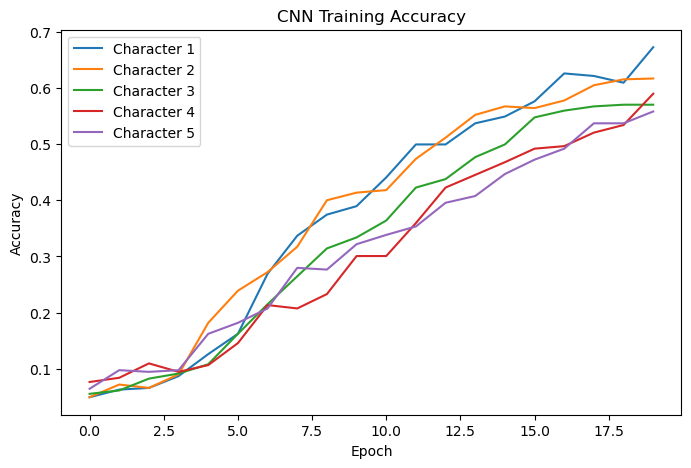

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["char_1_accuracy"],
    label="Character 1"
)

plt.plot(
    history.history["char_2_accuracy"],
    label="Character 2"
)

plt.plot(
    history.history["char_3_accuracy"],
    label="Character 3"
)

plt.plot(
    history.history["char_4_accuracy"],
    label="Character 4"
)

plt.plot(
    history.history["char_5_accuracy"],
    label="Character 5"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training Accuracy")
plt.legend()

plt.show()

In [10]:
results = model.evaluate(
    X_test,
    y_test_dict,
    verbose=1
)

print("Model evaluation completed.")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - char_1_accuracy: 0.6971 - char_1_loss: 1.1861 - char_2_accuracy: 0.5817 - char_2_loss: 1.4392 - char_3_accuracy: 0.5433 - char_3_loss: 1.5402 - char_4_accuracy: 0.4712 - char_4_loss: 1.7449 - char_5_accuracy: 0.4856 - char_5_loss: 1.6271 - loss: 7.5481
Model evaluation completed.


In [11]:
predictions = model.predict(X_test)

predicted_labels = []

for i in range(len(X_test)):

    captcha = ""

    for j in range(5):

        predicted_index = np.argmax(
            predictions[j][i]
        )

        captcha += characters[predicted_index]

    predicted_labels.append(captcha)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


In [12]:
actual_labels = []

for i in range(len(y_test)):

    captcha = "".join(
        characters[n]
        for n in y_test[i]
    )

    actual_labels.append(captcha)


correct = 0

for actual, predicted in zip(
    actual_labels,
    predicted_labels
):

    if actual == predicted:
        correct += 1


captcha_accuracy = (
    correct / len(actual_labels)
)

print(
    "Complete CAPTCHA Accuracy:",
    captcha_accuracy
)

Complete CAPTCHA Accuracy: 0.07211538461538461


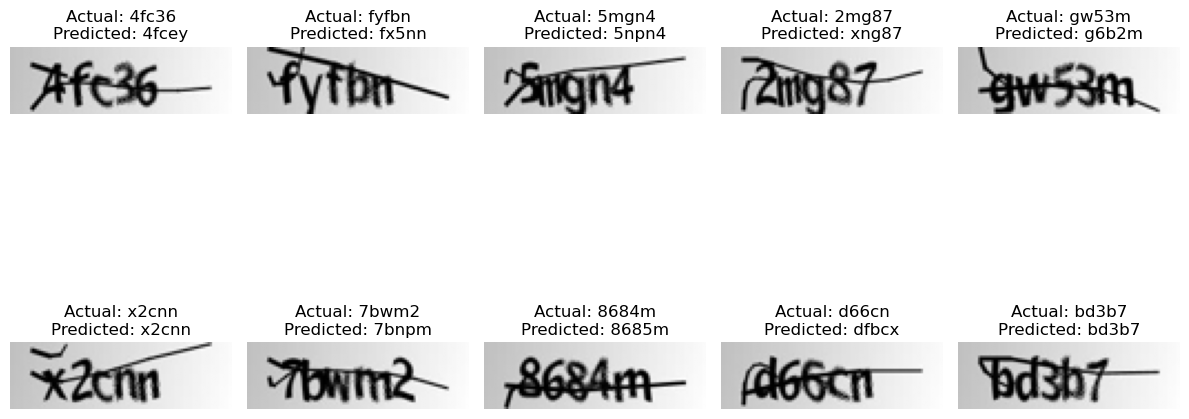

In [13]:
plt.figure(figsize=(12, 8))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    plt.title(
        f"Actual: {actual_labels[i]}\n"
        f"Predicted: {predicted_labels[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()